# P6 / 02: out-of-sample evaluation and gates

Protocol: [`001_claude_p6_deep_stat_arb_preregistration.md`](../../discussions/Deep_Statistical_Arbitrage/001_claude_p6_deep_stat_arb_preregistration.md), sections 3–4. Uses the cached dataset and network scores from notebook 01.

**Portfolio.** Weights are neutralised to the 5 PCA factors and scaled to Σ|w| = 1. They are traded at the close after the signal, with measured costs.

**Benchmarks** (reported only): OU s-score and 5-session linear reversal on the same residuals.

**Gates** per window (B 2017–2019, A 2020–2025):
- **G1** net bootstrap lower bound > 0;
- **G2** gross beats 1,000 weight permutations;
- **G3** net > 0 at 2× cost.

`EDGE_CANDIDATE` only if both windows pass.

In [1]:
import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p6, s04, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, session_schedule
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P6_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p6.P6Config()
CACHE = work_dir() / "results" / ("p6_synthetic" if SYNTHETIC else "p6")
CACHE.mkdir(parents=True, exist_ok=True)
if SYNTHETIC:
    CFG = replace(CFG, train_days=300, valid_days=100, refit_every=125, first_test="2017-01-03", end="2017-12-29",
                  seeds=(0, 1), epochs=3, patience=3, n_placebo=50, n_boot=2000)
OUT = ROOT / "notebooks" / "Deep_Statistical_Arbitrage" / ("02_synthetic" if SYNTHETIC else "02")
OUT.mkdir(parents=True, exist_ok=True)
DS = p6.load_dataset(CACHE / f"dataset_p6{p6.P6_VERSION}.npz")
SC = np.load(CACHE / "scores.npz")["scores"]
WINDOWS = {"B 2017-2019": ("2017-01-01", "2019-12-31"), "A 2020-2025": ("2020-01-01", "2025-12-31")}
if SYNTHETIC:
    WINDOWS = {"B 2017H1": ("2017-01-01", "2017-06-30"), "A 2017H2": ("2017-07-01", "2017-12-31")}
ROWS = np.flatnonzero(np.isfinite(SC).any(1))
ONES = np.ones(DS["ok"].shape)
W = {"model": p6.weights_from_scores(SC, ONES, DS["X"], DS["ok"])}
W["OU"] = p6.weights_from_scores(np.where(np.isfinite(SC), p6.ou_scores(DS["x"]), np.nan), ONES, DS["X"], DS["ok"])
W["linear"] = p6.weights_from_scores(np.where(np.isfinite(SC), p6.linear_scores(DS["x"]), np.nan), ONES, DS["X"], DS["ok"])
print(f"{len(ROWS)} prediction days, {DS['index'][ROWS[0]].date()} to {DS['index'][ROWS[-1]].date()}")

2260 prediction days, 2017-01-03 to 2025-12-29


## 1. Returns by window, cost level and strategy

total_return  sharpe  max_drawdown  days  \
window      strategy cost                                             
A 2020-2025 OU       0x         -0.0415 -0.2224        0.1455  1508   
                     1x         -0.2815 -1.8332        0.3417  1508   
                     2x         -0.4614 -3.4365        0.4953  1508   
            linear   0x          0.1664  0.4807        0.1232  1508   
                     1x         -0.1069 -0.3040        0.2216  1508   
                     2x         -0.3162 -1.0886        0.3780  1508   
            model    0x          0.1497  0.5681        0.1011  1508   
                     1x          0.0272  0.1263        0.1031  1508   
                     2x         -0.0823 -0.3155        0.1636  1508   
B 2017-2019 OU       0x         -0.0479 -0.8987        0.0702   752   
                     1x         -0.1391 -2.7557        0.1400   752   
                     2x         -0.2217 -4.6025        0.2218   752   
            linear   0x          0.0619  0.5972        0.0424   752   
                     1x         -0.0394 -0.3706        0.0791   752   
                     2x         -0.1310 -1.3371        0.1357   752   
            model    0x          0.0477  0.6262        0.0319   752   
                     1x          0.0081  0.1184        0.0436   752   
                     2x         -0.0301 -0.3891        0.0572   752   

                           net_bps_day  gross_bps_day  cost_bps_day  
window      strategy cost                                            
A 2020-2025 OU       0x        -0.2634        -0.2634        0.0000  
                     1x        -2.1740        -0.2634        1.9106  
                     2x        -4.0847        -0.2634        3.8213  
            linear   0x         1.0848         1.0848        0.0000  
                     1x        -0.6859         1.0848        1.7707  
                     2x        -2.4566         1.0848        3.5415  
            model    0x         0.9613         0.9613        0.0000  
                     1x         0.2137         0.9613        0.7475  
                     2x        -0.5338         0.9613        1.4951  
B 2017-2019 OU       0x        -0.6463        -0.6463        0.0000  
                     1x        -1.9857        -0.6463        1.3394  
                     2x        -3.3251        -0.6463        2.6788  
            linear   0x         0.8220         0.8220        0.0000  
                     1x        -0.5103         0.8220        1.3323  
                     2x        -1.8426         0.8220        2.6646  
            model    0x         0.6320         0.6320        0.0000  
                     1x         0.1195         0.6320        0.5125  
                     2x        -0.3930         0.6320        1.0250

mean daily turnover (sum |dw|, gross = 1): {'model': 0.262, 'OU': 0.723, 'linear': 0.634}


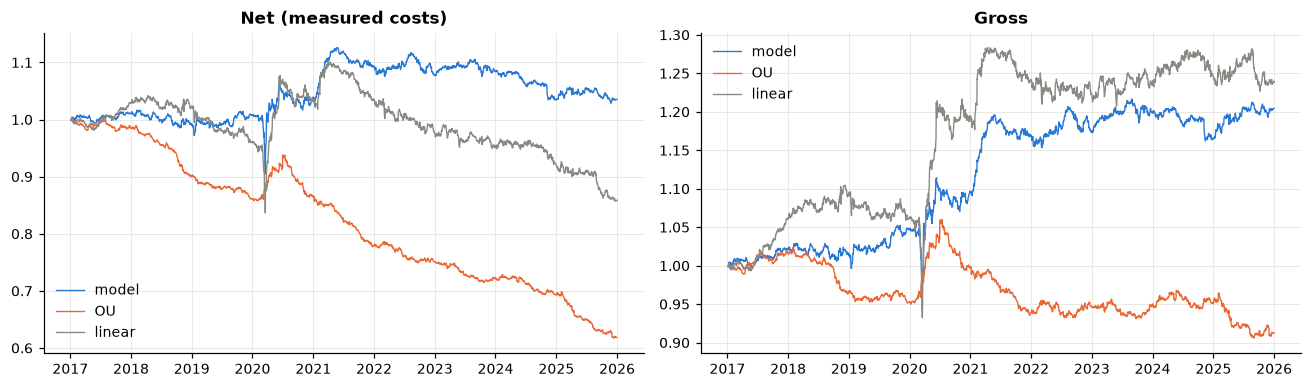

In [2]:
RES, TAB = {}, []
for name, Wm in W.items():
    for cm in (1.0, 2.0, 0.0):
        RES[(name, cm)] = p6.evaluate_rows(Wm, DS, ROWS, cm)
for (name, cm), df in RES.items():
    for wname, (a, b) in WINDOWS.items():
        x = df.loc[a:b]
        m = p6.series_metrics(x["net"])
        TAB.append({"strategy": name, "cost": f"{cm:g}x", "window": wname, **m, "net_bps_day": 1e4 * x.net.mean(),
                    "gross_bps_day": 1e4 * x.gross.mean(), "cost_bps_day": 1e4 * x.cost.mean()})
TAB = pd.DataFrame(TAB).set_index(["window", "strategy", "cost"]).sort_index()
TAB.to_csv(OUT / "results.csv", float_format="%.5g"); display(TAB.round(4))
turn = {n: float(np.abs(np.diff(Wm[ROWS], axis=0)).sum(1).mean()) for n, Wm in W.items()}
print("mean daily turnover (sum |dw|, gross = 1):", {k: round(v, 3) for k, v in turn.items()})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name, col in zip(W, ("#2a78d6", "#eb6834", "#8a8a84")):
    ax[0].plot((1 + RES[(name, 1.0)]["net"]).cumprod(), color=col, lw=0.9, label=name)
    ax[1].plot((1 + RES[(name, 0.0)]["gross"]).cumprod(), color=col, lw=0.9, label=name)
ax[0].set_title("Net (measured costs)"); ax[1].set_title("Gross")
for a in ax: a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 2. Gates (network)

In [3]:
G, RANKS, BOOT = {}, {}, {}
net, gross = RES[("model", 1.0)]["net"], RES[("model", 1.0)]["gross"]
idx_dates = pd.DatetimeIndex([DS["index"][min(r + 2, len(DS["index"]) - 1)] for r in ROWS])
for wname, (a, b) in WINDOWS.items():
    sel = (idx_dates >= a) & (idx_dates <= b)
    rows_w = ROWS[sel]
    BOOT[wname] = {k: p1.block_bootstrap(net.loc[a:b].to_numpy(), k, CFG.n_boot, CFG.seed, 0.05) for k in CFG.blocks}
    pg = p6.placebo_gross(W["model"], DS["ret"], DS["ok"], rows_w, CFG.n_placebo, CFG.seed)
    tot = np.prod(1 + pg, 1) - 1
    shp = np.sqrt(252) * pg.mean(1) / pg.std(1, ddof=1)
    g = gross.loc[a:b]
    RANKS[wname] = {"total_return": s04.placebo_rank(float(np.prod(1 + g) - 1), tot),
                    "sharpe": s04.placebo_rank(float(np.sqrt(252) * g.mean() / g.std()), shp)}
    G[wname] = p6.gates(BOOT[wname], RANKS[wname], p6.series_metrics(RES[("model", 2.0)]["net"].loc[a:b]))
display(pd.concat({w: pd.DataFrame(v, index=["mean", "lo95", "hi95"]).T * 1e4 for w, v in BOOT.items()}).round(3))
display(pd.concat({w: pd.DataFrame(v).T for w, v in RANKS.items()}).round(4)); display(pd.DataFrame(G))
YR = pd.DataFrame({n: RES[(n, 1.0)]["net"].groupby(RES[(n, 1.0)].index.year).apply(lambda x: (1 + x).prod() - 1) for n in W})
display((100 * YR).round(2))
VERDICT = "EDGE_CANDIDATE" if all(g["pass"] for g in G.values()) else "NO_EDGE"
print("verdict:", VERDICT)
summary = {"study": "P6-02", "synthetic": SYNTHETIC, "config": CFG.as_dict(), "windows": WINDOWS,
           "results": {"|".join(k): v for k, v in TAB.to_dict(orient="index").items()}, "turnover": turn,
           "bootstrap_bps": {w: {str(k): [1e4 * x for x in v] for k, v in b.items()} for w, b in BOOT.items()},
           "placebo_ranks_gross": RANKS, "gates": G, "net_by_year": {str(k): v for k, v in YR.to_dict(orient="index").items()},
           "verdict": VERDICT, "prospective_verdict": "PENDING_2026_HOLDOUT" if VERDICT == "EDGE_CANDIDATE" else "NOT_APPLICABLE",
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "p6": p6.P6_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir())}, indent=2))

mean   lo95   hi95
B 2017-2019 10  0.119 -1.129  1.389
            20  0.119 -1.021  1.189
            40  0.119 -0.838  0.958
A 2020-2025 10  0.214 -1.275  1.826
            20  0.214 -1.185  1.765
            40  0.214 -1.045  1.631

value  percentile  p_upper  placebo_median  \
B 2017-2019 total_return  0.0477        96.6   0.0350          0.0013   
            sharpe        0.6262        84.0   0.1608          0.0373   
A 2020-2025 total_return  0.1497       100.0   0.0010         -0.0162   
            sharpe        0.5681        97.0   0.0310         -0.1411   

                          placebo_p95  
B 2017-2019 total_return       0.0437  
            sharpe             1.0145  
A 2020-2025 total_return       0.0506  
            sharpe             0.4610

,B 2017-2019,A 2020-2025
G1_bootstrap,False,False
G2_vs_permuted_gross,False,True
G3_double_cost,False,False
pass,False,False


,model,OU,linear
2017,1.08,-1.48,2.82
2018,-1.81,-8.48,-0.46
2019,1.57,-4.53,-6.14
2020,2.91,0.52,7.49
2021,5.36,-9.90,0.22
2022,-1.29,-3.69,-5.42
2023,0.45,-3.77,-2.79
2024,-4.45,-4.16,-3.31
2025,-0.02,-10.67,-6.74


verdict: NO_EDGE


58